# Feature detection

## Harris Corner detection

As always we start with the imports

In [26]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

To start, we will use the same checkerboard image as earlier.

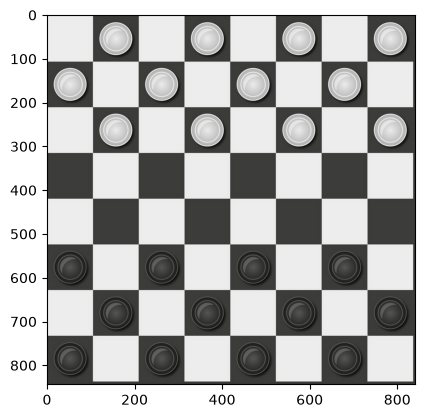

In [27]:
img = cv2.imread('checkers.png')
# Changing the order from bgr to rgb so that matplotlib can show it
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

### Exercise 2a
Fill in the missing code in the next block. We would like to detect the corners of the image using the OpenCV function [`cv2.cornerHarris`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#gac1fc3598018010880e370e2f709b4345). Afterwards we want to draw the location of the detected corners on the image and display it.

(np.float64(-0.5), np.float64(841.5), np.float64(843.5), np.float64(-0.5))

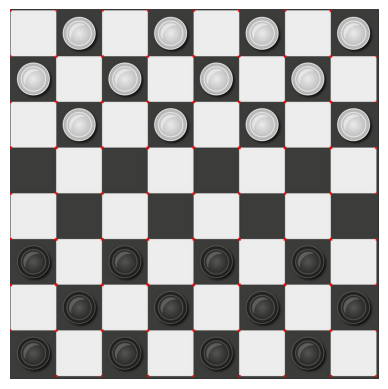

In [34]:
# Change image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
cimg = img.copy()  # Copy the original image to draw corners on
### Insert Harris Corner detector here ###
corners = cv2.cornerHarris(gray,
                           2, # The size of the local neighborhood (window) considered for corner detection
                           3, # Aperture parameter for the internal Sobel operator used to compute image gradients. It must be an odd number (3)
                           0.04 # Harris free parameter in the score equation. It is typically set empirically between 0.04 and 0.06
                           )

corners = cv2.dilate(corners, None)  # Dilate to mark the corners
### Draw the detected corners in the original image here ###
cimg[corners > 0.01 * corners.max()] = [255, 0, 0]  # Mark corners in red

# Display image
plt.imshow(cimg)
plt.axis('off')


## Shi-Tomasi
Next we will try the Shi-Tomasi feature detection method. In OpenCV, that method is implemented as [`cv2.goodFeaturesToTrack`](https://docs.opencv.org/4.7.0/dd/d1a/group__imgproc__feature.html#ga1d6bb77486c8f92d79c8793ad995d541). 
Let's start with a different image this time.

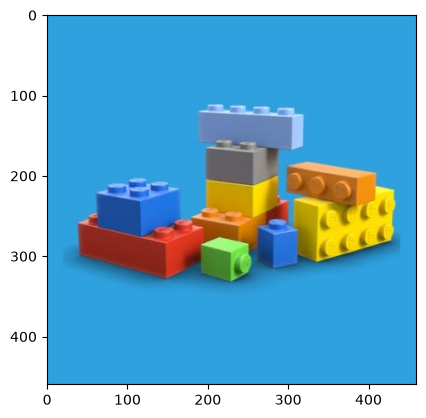

In [54]:
img = cv2.imread('Lego.jpg')
# Changing the order from bgr to rgb so that matplotlib can show it
b,g,r = cv2.split(img)
img = cv2.merge([r,g,b])
plt.imshow(img)

### Exercise 2b
Just like the previous exercise, detect the corners of the image by inserting the missing code, this time using the Shi-Tomasi (good features to track) method. Draw the detected corners on the image. Check the documentation of the function for help.

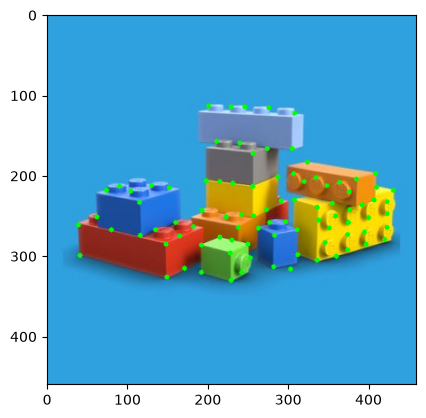

In [70]:
# Change image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
cimg = img.copy()  # Copy the original image to draw corners on

### Insert goodFeaturesToTrack detector here ###
corners = cv2.goodFeaturesToTrack(gray,
                               100, # Maximum number of corners to return. If there are more corners than are found, the strongest of them is returned
                               0.005, # Quality level parameter. It is a value between 0 and 1, which indicates the minimum quality of corners to be considered
                               15) # Minimum Euclidean distance between corners detected
### Draw the detected corners in the original image here ###
corners = np.int32(corners)

for i in corners:
    # i.ravel() flattens [[x, y]] down to [x, y]
    x, y = i.ravel()
    # Draw a clean solid circle on every corner
    cv2.circle(cimg, (x, y), 3, (0, 255, 0), -1)

# Display image
plt. imshow(cimg)

### Exercise 2c
Do a Harris corner detection on the same Lego image and compare the result with the Shi-Tomasi image.

(np.float64(-0.5), np.float64(459.5), np.float64(459.5), np.float64(-0.5))

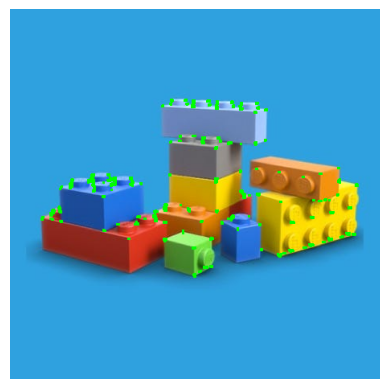

In [85]:
# Change image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
cimg = img.copy()  # Copy the original image to draw corners on
### Insert Harris Corner detector here ###
corners = cv2.cornerHarris(gray,
                           3, # The size of the local neighborhood (window) considered for corner detection
                           3, # Aperture parameter for the internal Sobel operator used to compute image gradients. It must be an odd number (3)
                           0.06 # Harris free parameter in the score equation. It is typically set empirically between 0.04 and 0.06
                           )

corners = cv2.dilate(corners, None)  # Dilate to mark the corners
### Draw the detected corners in the original image here ###
cimg[corners > 0.01 * corners.max()] = [0, 255, 0]  # Mark corners in red

# Display image
plt.imshow(cimg)
plt.axis('off')